# 02 — Exploratory Analysis of Engineered Features

This notebook checks whether the behavioural features in `src/credit_risk/features.py` carry signal. It uses the **training partition only**, so nothing about the validation or test sets shapes the feature design.

All rates here are **observed associations, not causal effects**.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from credit_risk.config import load_config, resolve_path
BLUE, ORANGE, AQUA, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a9a", "#1f1f1f", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "axes.axisbelow": True, "figure.dpi": 110})
FIG_DIR = resolve_path("reports/figures")
pd.set_option("display.width", 160); pd.set_option("display.precision", 4)
from credit_risk.data import DataSplits, TARGET, apply_splits, load_raw, split_features_target, standardize_columns
from credit_risk.features import ENGINEERED_FEATURES, CreditFeatureEngineer
cfg = load_config("data")
df = standardize_columns(load_raw(resolve_path(cfg["dataset"]["raw_path"])))
train, _, _ = apply_splits(df, DataSplits.from_json(resolve_path(cfg["split"]["output_path"])))
X, y = split_features_target(train)
F = CreditFeatureEngineer().fit_transform(X)
print(f"Training rows: {len(F):,}   default rate: {y.mean():.2%}")
F[ENGINEERED_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]

Training rows: 18,000   default rate: 22.12%


,mean,std,min,50%,max
utilization_1,0.4214,0.4120,-0.6199,0.3096,6.4553
utilization_mean,0.3708,0.3513,-0.2326,0.2816,5.3643
utilization_max,0.4928,0.4299,-0.1000,0.4265,6.4553
bill_trend,0.1048,0.3021,-1.6142,0.0066,5.3095
payment_to_bill_ratio,0.3930,0.7777,0.0000,0.0879,10.0000
payment_1_to_limit,0.0447,0.0984,0.0000,0.0250,2.5693
months_delayed,0.8414,1.5535,0.0000,0.0000,6.0000
max_delay,0.6866,1.0686,0.0000,0.0000,8.0000
recent_delays_3m,0.5202,0.9504,0.0000,0.0000,3.0000
delay_trend,0.1307,0.8282,-6.0000,0.0000,6.0000


## Univariate discrimination
The ROC-AUC of each feature used alone as a score (values below 0.5 mean higher values go with *lower* risk; |AUC − 0.5| measures strength).

,univariate_auc
months_delayed,0.7313
max_delay,0.7207
recent_delays_3m,0.7183
PAY_1,0.6963
delay_trend,0.5887
utilization_mean,0.5675
utilization_1,0.5531
utilization_max,0.5523
inactive_account,0.5116
months_zero_bill,0.4989


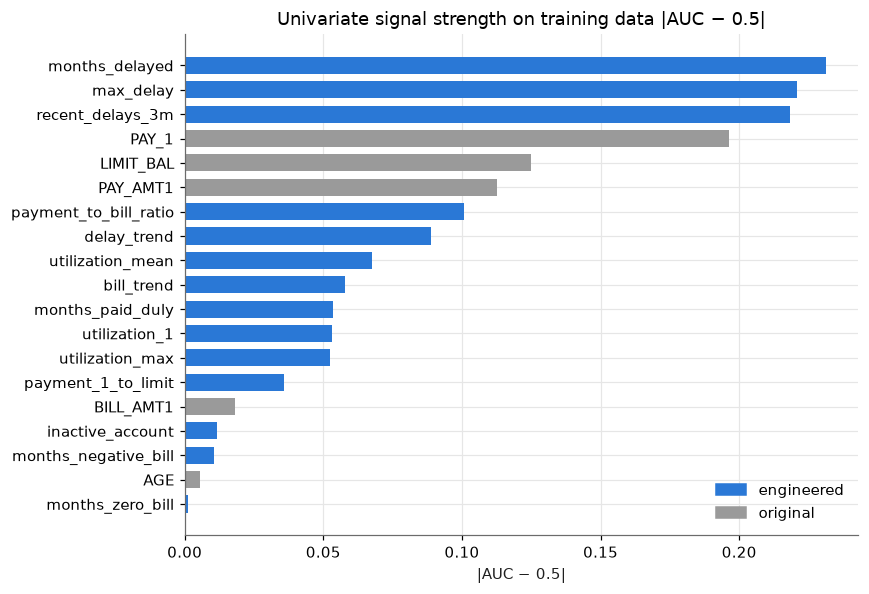

In [2]:
from sklearn.metrics import roc_auc_score
cols = ["LIMIT_BAL", "AGE", "PAY_1", "BILL_AMT1", "PAY_AMT1"] + ENGINEERED_FEATURES
auc = pd.Series({c: roc_auc_score(y, F[c]) for c in cols}, name="univariate_auc")
strength = (auc - 0.5).abs().sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [BLUE if c in ENGINEERED_FEATURES else GREY for c in strength.index]
ax.barh(strength.index, strength.values, color=colors, height=0.7)
ax.set(title="Univariate signal strength on training data |AUC − 0.5|", xlabel="|AUC − 0.5|")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREY)],
          labels=["engineered", "original"], frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_univariate_auc.png", bbox_inches="tight")
auc.sort_values(ascending=False).to_frame()

Delay-history features (`max_delay`, `months_delayed`, `recent_delays_3m`) are the strongest single signals, as expected from the audit. Utilisation adds a separate dimension. Payment ratios go with lower risk (AUC < 0.5).

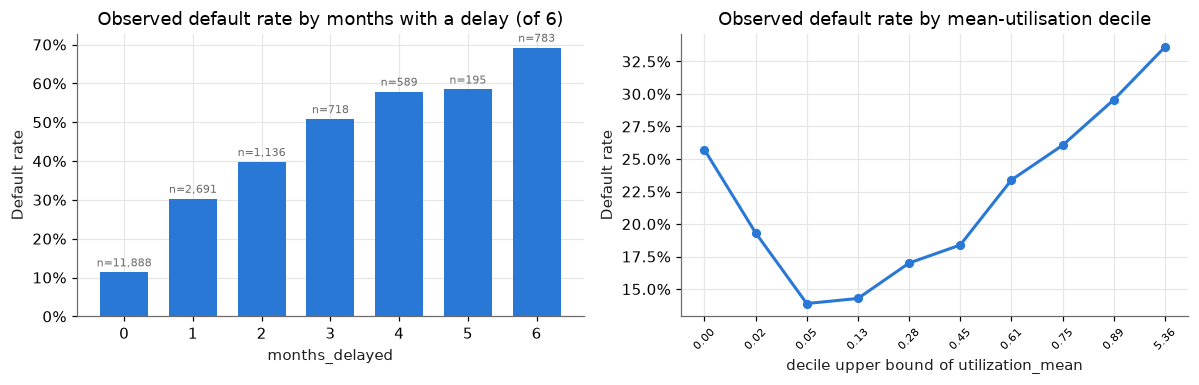

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
g = pd.DataFrame({"months_delayed": F["months_delayed"], "y": y}).groupby("months_delayed")["y"].agg(["mean", "size"])
axes[0].bar(g.index, g["mean"], color=BLUE, width=0.7)
for x, (m, n) in zip(g.index, g.itertuples(index=False)):
    axes[0].text(x, m + 0.015, f"n={n:,}", ha="center", fontsize=7, color=MUTED)
axes[0].set(title="Observed default rate by months with a delay (of 6)", xlabel="months_delayed", ylabel="Default rate")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
bins = pd.qcut(F["utilization_mean"], 10, duplicates="drop")
u = pd.DataFrame({"b": bins, "y": y}).groupby("b", observed=True)["y"].mean()
axes[1].plot(range(len(u)), u.values, color=BLUE, lw=2, marker="o", ms=5)
axes[1].set_xticks(range(len(u)), [f"{iv.right:.2f}" for iv in u.index], rotation=45, fontsize=7)
axes[1].set(title="Observed default rate by mean-utilisation decile", xlabel="decile upper bound of utilization_mean", ylabel="Default rate")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
fig.tight_layout(); fig.savefig(FIG_DIR / "02_delay_utilisation.png", bbox_inches="tight")

**Takeaways for modelling**
- Risk climbs steeply with the number of months in arrears. For Logistic Regression, one-hot `PAY_k` plus the count features capture this non-linearity.
- The utilisation–risk relationship is non-linear (not monotonic at low utilisation), which tree models may exploit better than a linear model.
- Correlated features share the signal, so individual coefficients should not be read in isolation (see notebook 03).